# Figure 5: Sprox-seq human tonsil, section B1

From the GEO count matrices (GSE304749) to every panel of Fig. 5: RNA and 46-probe protein targets, Saturn fit (seed 42),
marker compartments, axis readouts, domains, and the 1,692 held-out PLA products along both isodepths.
All panels of Fig. 5 involve Saturn, so none is dropped. The baseline benchmark (`sproxseq_baselines`, the main of
`sproxseq_ccc`) is not part of the figure and is not run here; the figure only takes the rotation helper and the
contact-pair list from `sproxseq_ccc`.

**Conda env:** `spatialmultivelo`. **Device:** CPU.

In [1]:
import sys; sys.path[:0] = [".", "steps"]
from pathlib import Path
import json
import nbutil as nb
from fig5_compare import compare_npz, compare_json, compare_png, show_small
nb.init("fig5")
STEPS = Path("steps").resolve()
SECS = ["A1", "B1", "D1"]; FIT = "sproxseq_B1_p46_dr"; T5 = "results/real_saturn/sproxseq_B1_fig5"

ok      external_data/sproxseq/GSM9156293_A1_barcodes.tsv.gz  [GEO GSE304749, GSM9156293 (Visium RNA, section A1; Wang et al., Cell 2026)]
ok      external_data/sproxseq/GSM9156293_A1_features.tsv.gz  [GEO GSE304749, GSM9156293 (Visium RNA, section A1; Wang et al., Cell 2026)]
ok      external_data/sproxseq/GSM9156293_A1_matrix.mtx.gz  [GEO GSE304749, GSM9156293 (Visium RNA, section A1; Wang et al., Cell 2026)]
ok      external_data/sproxseq/GSM9156293_A1_tissue_positions.csv.gz  [GEO GSE304749, GSM9156293 (Visium RNA, section A1; Wang et al., Cell 2026)]
ok      external_data/sproxseq/GSM9156300_A1-PLA_count_matrix.txt.gz  [GEO GSE304749, GSM9156300 (PLA counts, section A1)]
ok      external_data/sproxseq/GSM9156294_B1_barcodes.tsv.gz  [GEO GSE304749, GSM9156294 (Visium RNA, section B1; Wang et al., Cell 2026)]
ok      external_data/sproxseq/GSM9156294_B1_features.tsv.gz  [GEO GSE304749, GSM9156294 (Visium RNA, section B1; Wang et al., Cell 2026)]
ok      external_data/sproxseq/GSM915

## 1. Targets
RNA: Visium counts to 10 GLM-PCs. Protein: every PLA product containing a probe is summed into 46 probe marginals, then
CLR and 10 PCs. The PLA products are stored next to the target and never enter the loss. All three sections are prepared
because step 4 (`sproxseq_gc_trajectory.py`) loops over them.

**The GLM-PCs are not reproducible from the raw counts.** `glmpca` starts from an unseeded `np.random` draw, so each run
gives another rotation of the factors. The first comparison below (fresh draw vs published) shows it: everything is
bitwise identical except `Y_RNA`. The published draw is stored in `steps/fig5_glmpc_published.npz` (published `Y_RNA` only)
and is put back by `steps/fig5_pin_glmpc.py`, so the rest of the notebook can be checked against the published results.
Section 8 runs the same chain on a fresh draw to show what that draw changes.

In [2]:
for s in SECS:
    nb.step(f"prep_{s}", f"python scripts/sproxseq_prep.py {s} --probe",
            [f"results/real_saturn/targets_sproxseq_{s}_p46.npz", f"results/real_saturn/sproxseq_{s}_p46_pla.npz"])
    compare_npz(f"sproxseq_{s}_p46_pla.npz")
PINNED = nb.RES / "fig5_glmpc_pinned.txt"
if not PINNED.exists():
    for s in SECS: compare_npz(f"targets_sproxseq_{s}_p46.npz")     # fresh draw: only Y_RNA should differ
nb.step("pin_glmpc", f"python {STEPS}/fig5_pin_glmpc.py A1 B1 D1", [PINNED])
for s in SECS: compare_npz(f"targets_sproxseq_{s}_p46.npz")         # after pinning: nothing should differ

[skip] prep_A1: outputs exist
sproxseq_A1_p46_pla.npz keys only here [] only published []
  7 arrays compared, 7 identical; others: {}
[skip] prep_B1: outputs exist
sproxseq_B1_p46_pla.npz keys only here [] only published []


  7 arrays compared, 7 identical; others: {}
[skip] prep_D1: outputs exist
sproxseq_D1_p46_pla.npz keys only here [] only published []


  7 arrays compared, 7 identical; others: {}
[skip] pin_glmpc: outputs exist
targets_sproxseq_A1_p46.npz keys only here [] only published []
  69 arrays compared, 69 identical; others: {}
targets_sproxseq_B1_p46.npz keys only here [] only published []
  69 arrays compared, 69 identical; others: {}
targets_sproxseq_D1_p46.npz keys only here [] only published []
  69 arrays compared, 69 identical; others: {}


Each modality's own log depth is regressed from its factors and the factors rescaled. Fig. 5 uses section B1 only.

In [3]:
nb.step("depthreg_B1", "python scripts/sproxseq_prep_depthreg.py B1", [f"results/real_saturn/targets_{FIT}.npz"])
compare_npz(f"targets_{FIT}.npz")

[skip] depthreg_B1: outputs exist
targets_sproxseq_B1_p46_dr.npz keys only here [] only published []
  69 arrays compared, 69 identical; others: {}


{'Y_Protein': 0.0,
 'Y_RNA': 0.0,
 'ann_pla_total': 0.0,
 'barcodes': 'equal',
 'coords': 0.0,
 'coords_z': 0.0,
 'depth_Protein': 0.0,
 'depth_RNA': 0.0,
 'mk_AICDA': 0.0,
 'mk_BCL6': 0.0,
 'mk_CD19': 0.0,
 'mk_CD27': 0.0,
 'mk_CD3E': 0.0,
 'mk_CR2': 0.0,
 'mk_CXCL13': 0.0,
 'mk_FDCSP': 0.0,
 'mk_ICAM1': 0.0,
 'mk_ITGA4': 0.0,
 'mk_MKI67': 0.0,
 'mk_MS4A1': 0.0,
 'mk_PRDM1': 0.0,
 'mk_VCAM1': 0.0,
 'mk_prot_CD11a_B': 0.0,
 'mk_prot_CD147': 0.0,
 'mk_prot_CD19': 0.0,
 'mk_prot_CD20': 0.0,
 'mk_prot_CD21': 0.0,
 'mk_prot_CD23': 0.0,
 'mk_prot_CD24_A': 0.0,
 'mk_prot_CD24_B': 0.0,
 'mk_prot_CD279_B': 0.0,
 'mk_prot_CD27_A': 0.0,
 'mk_prot_CD27_B': 0.0,
 'mk_prot_CD28_A': 0.0,
 'mk_prot_CD28_B': 0.0,
 'mk_prot_CD29_A': 0.0,
 'mk_prot_CD29_B': 0.0,
 'mk_prot_CD3': 0.0,
 'mk_prot_CD32': 0.0,
 'mk_prot_CD35': 0.0,
 'mk_prot_CD38': 0.0,
 'mk_prot_CD4': 0.0,
 'mk_prot_CD40_B': 0.0,
 'mk_prot_CD8': 0.0,
 'mk_prot_CD81': 0.0,
 'mk_prot_CD86_A': 0.0,
 'mk_prot_CD86_B': 0.0,
 'mk_prot_CD9': 0.0,
 

## 2. Saturn fit on B1
`run_real2.py --dataset sproxseq_B1_p46_dr --seeds 1 --seed0 42`, the command in the session of 2026-10-14. That command
set no thread variable, so `SAT_THREADS` takes the script default of 4 and `OMP_NUM_THREADS` stays unset. Thread count
changes the fit. About 5 min.

Tested result: `axes.csv` and the weights are identical to the published ones. Two summary fields still differ: R2 by
about 2e-8, and `axis_axis_corr`, which is +0.107 in the published summary but -0.107 here. The published `axes.csv`
itself gives Spearman -0.107, so the published summary does not match its own axes in sign. No panel reads this field.

In [4]:
nb.step("fit_B1_dr", f"python scripts/run_real2.py --dataset {FIT} --seeds 1 --seed0 42", [f"results/real_saturn/{FIT}/axes.csv"], threads=4)
nb.compare_axes(FIT)
compare_json(f"{FIT}/summary.json")

[skip] fit_B1_dr: outputs exist
           dataset      axis  max_abs_diff  abs_r
sproxseq_B1_p46_dr     d_RNA           0.0    1.0
sproxseq_B1_p46_dr d_Protein           0.0    1.0
sproxseq_B1_p46_dr/summary.json: 8 leaves differ
  /R2_whole/Protein/full: here 0.5574136636800273 | published 0.5574136455407304
  /R2_whole/Protein/other_axes_only: here 0.23840116697541613 | published 0.2384012172284644
  /R2_whole/Protein/own_axis_only: here 0.4277967806992562 | published 0.42779679697253437
  /R2_whole/RNA/full: here 0.6105608960291697 | published 0.6105608955602372
  /R2_whole/RNA/other_axes_only: here 0.27780333173244265 | published 0.27780331958099247
  /R2_whole/RNA/own_axis_only: here 0.441754188754478 | published 0.44175420372971286
  /axis_axis_corr[0][1]: here -0.107 | published 0.107
  /axis_axis_corr[1][0]: here -0.107 | published 0.107


[('/R2_whole/Protein/full', 0.5574136636800273, 0.5574136455407304),
 ('/R2_whole/Protein/other_axes_only',
  0.23840116697541613,
  0.2384012172284644),
 ('/R2_whole/Protein/own_axis_only', 0.4277967806992562, 0.42779679697253437),
 ('/R2_whole/RNA/full', 0.6105608960291697, 0.6105608955602372),
 ('/R2_whole/RNA/other_axes_only', 0.27780333173244265, 0.27780331958099247),
 ('/R2_whole/RNA/own_axis_only', 0.441754188754478, 0.44175420372971286),
 ('/axis_axis_corr[0][1]', -0.107, 0.107),
 ('/axis_axis_corr[1][0]', -0.107, 0.107)]

## 3. Fits without depth regression
`sproxseq_gc_trajectory.py` reads the barcodes, coordinates and axes of the non-regressed p46 fits of all three sections.
The Fig. 5 tables only take barcodes and coordinates from them. The command of 2026-09-20 is not in the transcripts, so
the run uses the same defaults as step 2. These axes are compared but do not feed any panel.

In [5]:
for s in SECS:
    nb.step(f"fit_{s}_p46", f"python scripts/run_real2.py --dataset sproxseq_{s}_p46 --seeds 1 --seed0 42",
            [f"results/real_saturn/sproxseq_{s}_p46/axes.csv"], threads=4)
    nb.compare_axes(f"sproxseq_{s}_p46")

[skip] fit_A1_p46: outputs exist
        dataset      axis  max_abs_diff  abs_r
sproxseq_A1_p46     d_RNA           0.0    1.0
sproxseq_A1_p46 d_Protein           0.0    1.0
[skip] fit_B1_p46: outputs exist
        dataset      axis  max_abs_diff  abs_r
sproxseq_B1_p46     d_RNA           0.0    1.0
sproxseq_B1_p46 d_Protein           0.0    1.0
[skip] fit_D1_p46: outputs exist
        dataset      axis  max_abs_diff  abs_r
sproxseq_D1_p46     d_RNA           0.0    1.0
sproxseq_D1_p46 d_Protein           0.0    1.0


## 4. Marker zones and Pearson residuals
Follicle zones from the authors' marker lists, per-spot Pearson residuals of the PLA products. The script also runs its
200-rotation tests on all three sections; those are not used by the figure. OMP unset, as published.

In [6]:
G = "results/real_saturn/sproxseq_gc_trajectory"
nb.step("gc_trajectory", "python scripts/sproxseq_gc_trajectory.py", [f"{G}/spots_{s}.csv" for s in SECS] + [f"{G}/residuals_B1.npy"])
nb.compare_table("sproxseq_gc_trajectory/spots_B1.csv", tol=1e-6)

[skip] gc_trajectory: outputs exist
sproxseq_gc_trajectory/spots_B1.csv: shape (3204, 11) vs (3204, 11); max numeric diff 0; MATCH


{'file': 'sproxseq_gc_trajectory/spots_B1.csv',
 'same_shape': True,
 'max_diff': 0.0}

## 5. Axis readouts on B1
The protein-axis readout (`bt_axis`) feeds the joint table of the RNA-axis readout (`rna_axis`), which writes the
compartments, axis orientation, mitochondrial share and depth used by the figure. 200 rotations for genes and complexes.
`OMP_NUM_THREADS=16`, as published.

In [7]:
nb.step("bt_axis", "python scripts/sproxseq_B1_bt_axis.py", ["results/real_saturn/sproxseq_B1_bt_axis/complexes.csv"], omp=16)
nb.step("rna_axis", "python scripts/sproxseq_B1_rna_axis.py", ["results/real_saturn/sproxseq_B1_rna_axis/spots.csv"], omp=16)
for t in ("sproxseq_B1_bt_axis/complexes.csv", "sproxseq_B1_rna_axis/spots.csv", "sproxseq_B1_rna_axis/complexes.csv", "sproxseq_B1_rna_axis/modules.csv"):
    nb.compare_table(t, tol=1e-4)

[skip] bt_axis: outputs exist
[skip] rna_axis: outputs exist
sproxseq_B1_bt_axis/complexes.csv: shape (849, 7) vs (849, 7); max numeric diff 0; MATCH


sproxseq_B1_rna_axis/spots.csv: shape (3204, 9) vs (3204, 9); max numeric diff 0; MATCH
sproxseq_B1_rna_axis/complexes.csv: shape (849, 13) vs (849, 13); max numeric diff 0; MATCH
sproxseq_B1_rna_axis/modules.csv: shape (9, 5) vs (9, 5); max numeric diff 0; MATCH


## 6. Fig. 5 tables
GASTON DP domains on each axis with K from the elbow, proteins with A/B probes summed, isotype-corrected complex
specificity per bin, and the slope of each complex against 200 rotations of the axis field. About 30 min, OMP unset.

In [8]:
nb.step("fig5_tables", "python scripts/sproxseq_B1_fig5_prep.py", [f"{T5}/{f}" for f in ("spots.csv", "summary.json", "layers.npz", "proteins.npz", "complexes_RNA.csv", "complexes_Protein.csv")])
for t in ("spots.csv", "bins_RNA.csv", "bins_Protein.csv", "complexes_RNA.csv", "complexes_Protein.csv", "profiles_RNA.csv", "profiles_Protein.csv"):
    nb.compare_table(f"sproxseq_B1_fig5/{t}", tol=1e-4)
compare_json("sproxseq_B1_fig5/summary.json"); compare_npz("sproxseq_B1_fig5/proteins.npz"); compare_npz("sproxseq_B1_fig5/layers.npz")

[skip] fig5_tables: outputs exist
sproxseq_B1_fig5/spots.csv: shape (3204, 13) vs (3204, 13); max numeric diff 0; MATCH
sproxseq_B1_fig5/bins_RNA.csv: shape (30, 3) vs (30, 3); max numeric diff 0; MATCH
sproxseq_B1_fig5/bins_Protein.csv: shape (30, 3) vs (30, 3); max numeric diff 0; MATCH
sproxseq_B1_fig5/complexes_RNA.csv: shape (645, 5) vs (645, 5); max numeric diff 1.11e-16; MATCH
sproxseq_B1_fig5/complexes_Protein.csv: shape (645, 5) vs (645, 5); max numeric diff 2.01e-16; MATCH
sproxseq_B1_fig5/profiles_RNA.csv: shape (30, 646) vs (30, 646); max numeric diff 8.88e-16; MATCH
sproxseq_B1_fig5/profiles_Protein.csv: shape (30, 646) vs (30, 646); max numeric diff 1.33e-15; MATCH
sproxseq_B1_fig5/summary.json: 0 leaves differ
sproxseq_B1_fig5/proteins.npz keys only here [] only published []
  3 arrays compared, 3 identical; others: {}
sproxseq_B1_fig5/layers.npz keys only here [] only published []


  6 arrays compared, 5 identical; others: {'IE': 1.4210854715202004e-14}


{'E': 0.0,
 'IE': 1.4210854715202004e-14,
 'IO': 0.0,
 'O': 0.0,
 'pairs': 'equal',
 'tg': 'equal'}

## 7. Figure
`fig5_B1.py` builds both pages (panels a to j) and one SVG per panel. Panel j fits the contact complexes inside the
builder. No panel is dropped.

[run ] figure: python /tmp/claude-1012/-mnt-HDD2B-Users-yancui/486f3289-97a4-41e8-a0a8-b5998a356a68/scratchpad/nbtest/fig5/Saturn/published_figures/fig5/fig5_B1.py


[done] figure: 0.3 min


fig5/fig5_part1.json: 2 leaves differ
  /png: here /tmp/claude-1012/-mnt-HDD2B-Users-yancui/486f3289-97a4-41e8-a0a8-b5998a356a68/scratchpad/nbtest/fig5/Saturn/published_figures/fig5/fig5_part1.png | published /mnt/HDD2B/Users/yancui/Saturn/published_figures/fig5/fig5_part1.png
  /svg: here /tmp/claude-1012/-mnt-HDD2B-Users-yancui/486f3289-97a4-41e8-a0a8-b5998a356a68/scratchpad/nbtest/fig5/Saturn/published_figures/fig5/fig5_part1.svg | published /mnt/HDD2B/Users/yancui/Saturn/published_figures/fig5/fig5_part1.svg
fig5/fig5_part2.json: 2 leaves differ
  /png: here /tmp/claude-1012/-mnt-HDD2B-Users-yancui/486f3289-97a4-41e8-a0a8-b5998a356a68/scratchpad/nbtest/fig5/Saturn/published_figures/fig5/fig5_part2.png | published /mnt/HDD2B/Users/yancui/Saturn/published_figures/fig5/fig5_part2.png
  /svg: here /tmp/claude-1012/-mnt-HDD2B-Users-yancui/486f3289-97a4-41e8-a0a8-b5998a356a68/scratchpad/nbtest/fig5/Saturn/published_figures/fig5/fig5_part2.svg | published /mnt/HDD2B/Users/yancui/Saturn/pu

fig5/fig5_part1.png: 4178x7001 px; largest channel difference 0; 0.00% of pixels differ


fig5/fig5_part2.png: 4782x7672 px; largest channel difference 0; 0.00% of pixels differ


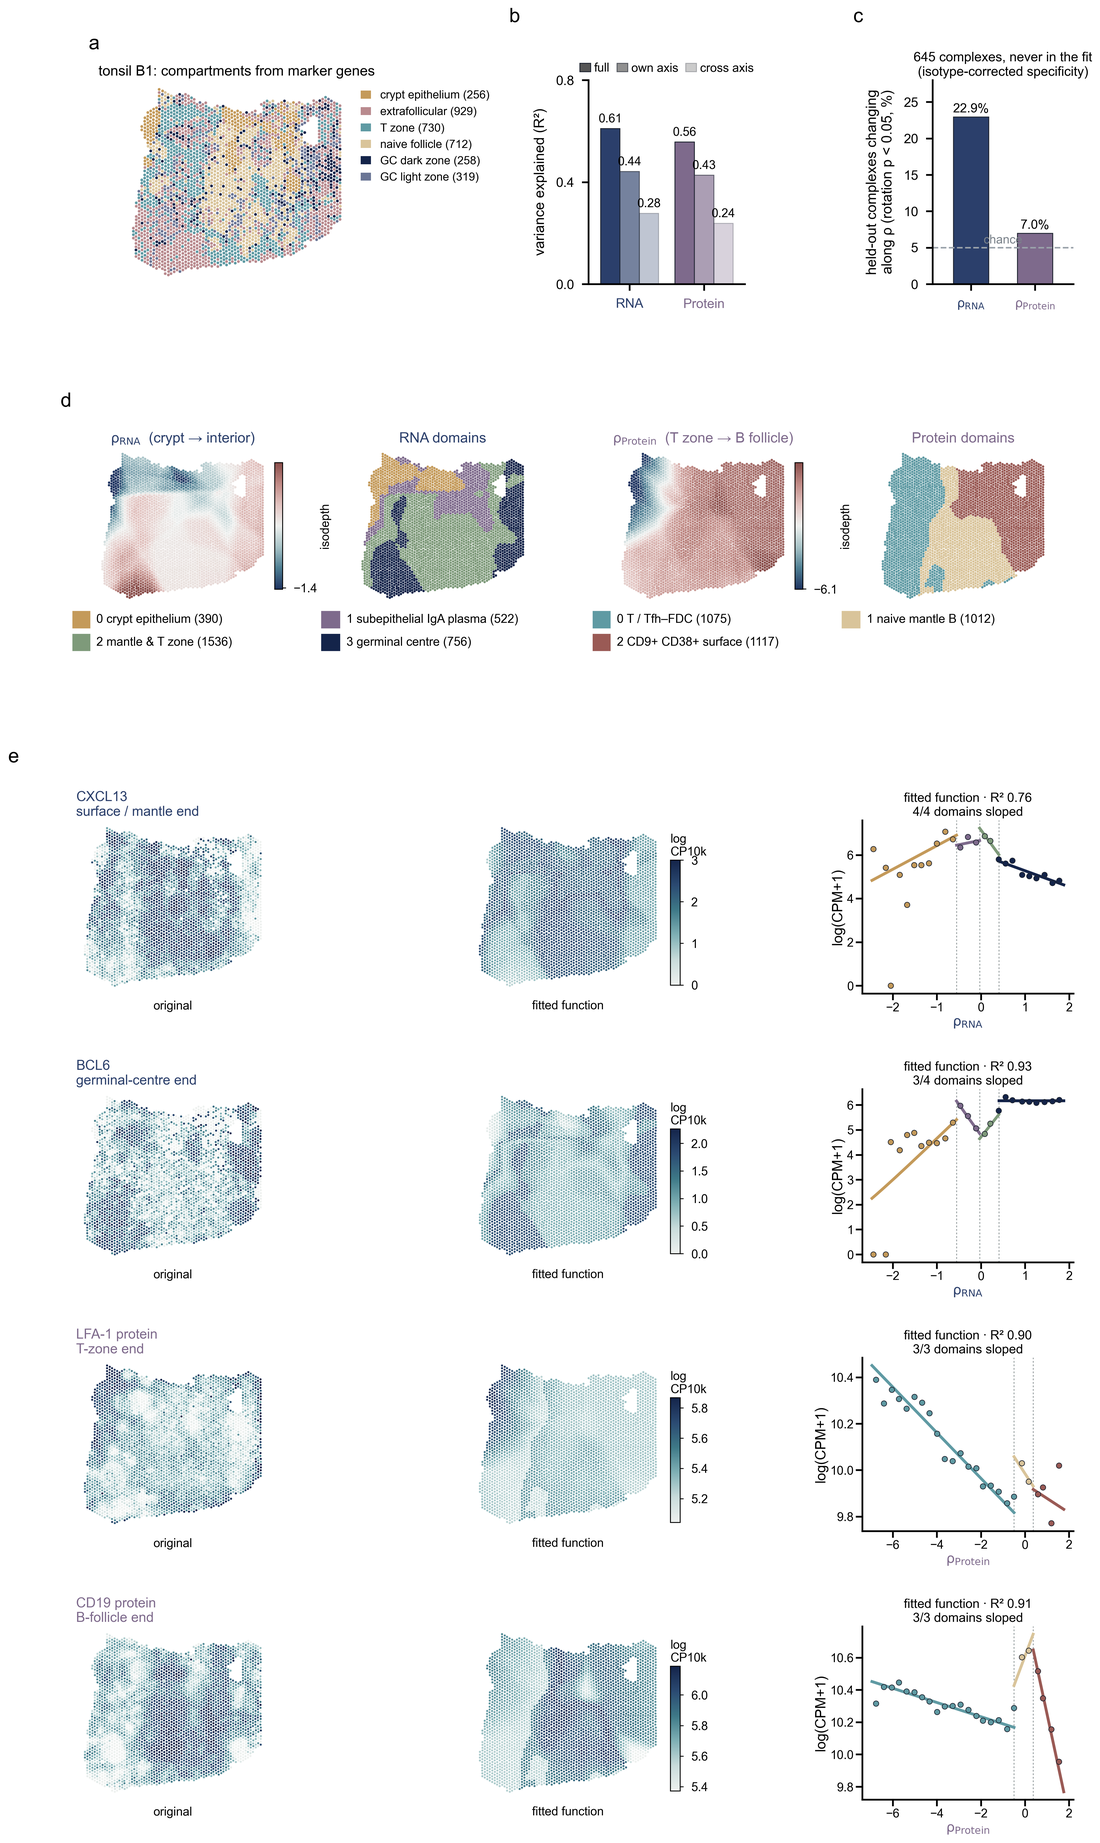

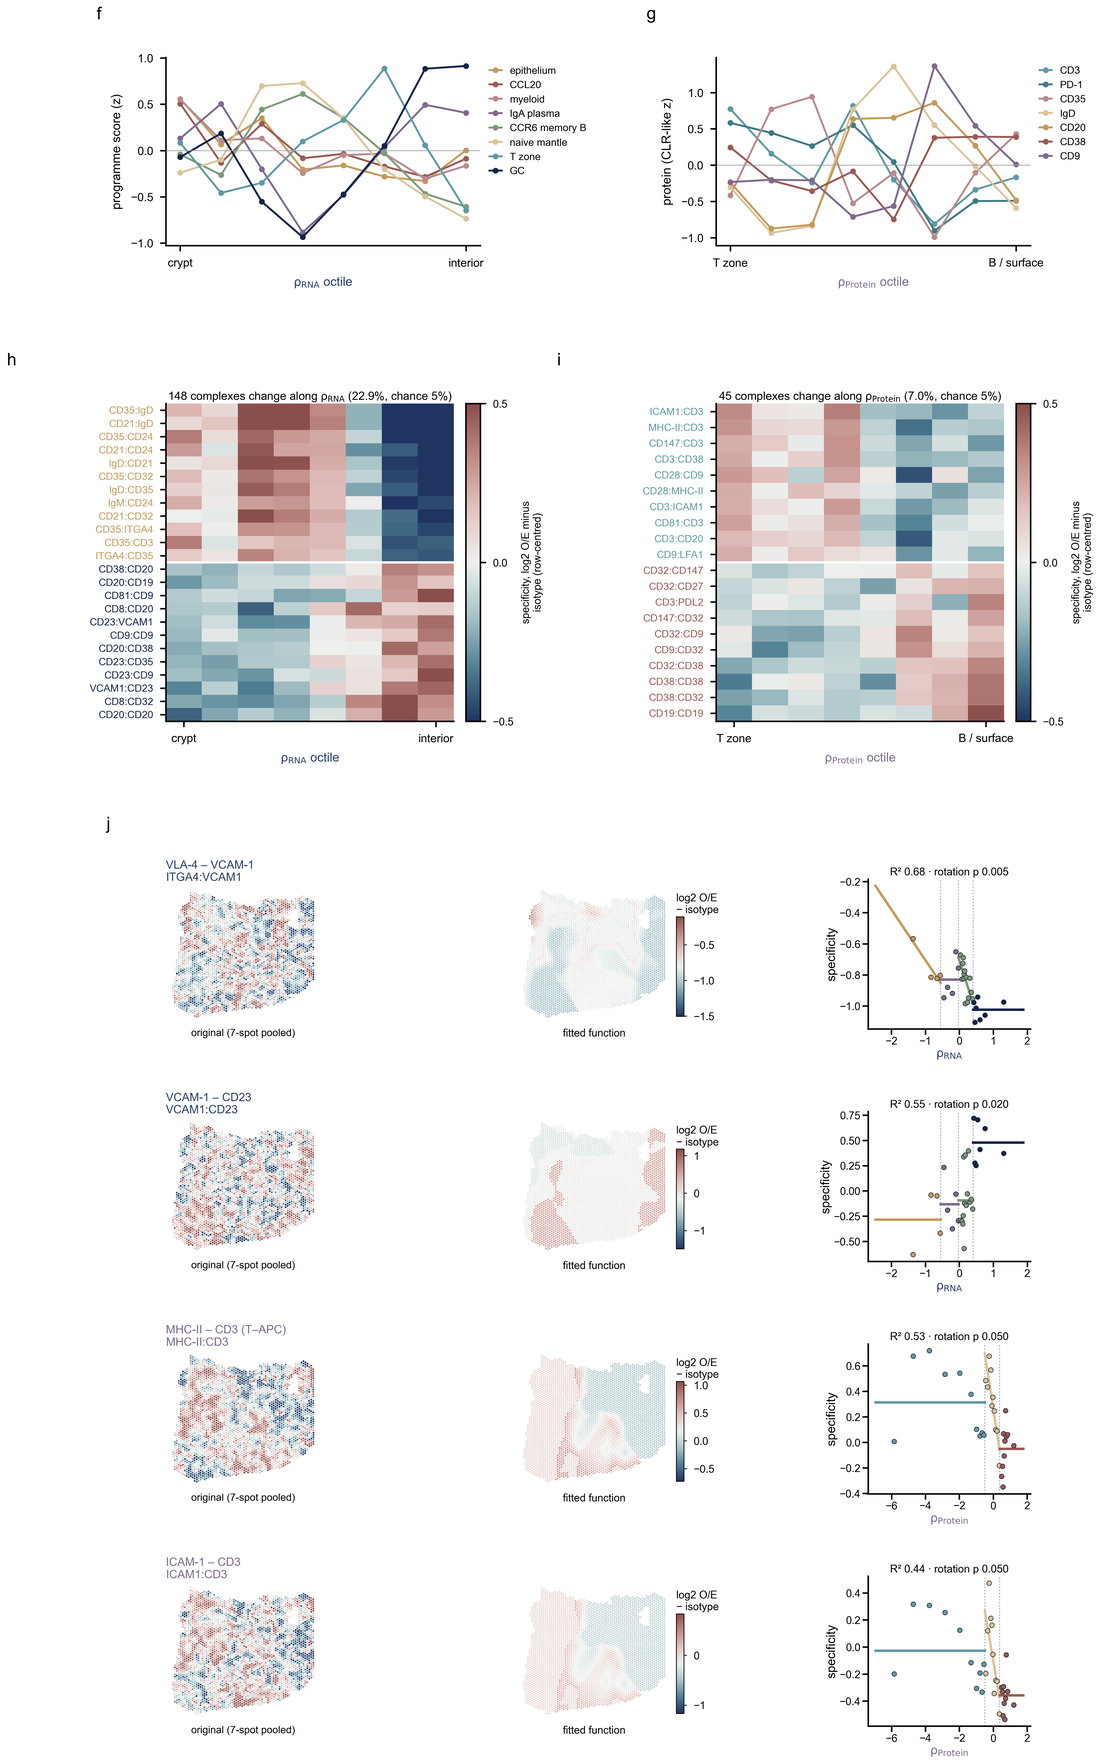

In [9]:
nb.step("figure", f"python {nb.PF}/fig5/fig5_B1.py")
compare_json("fig5/fig5_part1.json", root="pf"); compare_json("fig5/fig5_part2.json", root="pf")     # only the output paths differ
compare_png("fig5/fig5_part1.png"); compare_png("fig5/fig5_part2.png")
show_small("fig5/fig5_part1.png", "fig5/fig5_part2.png")

## 8. Replicate with a fresh GLM-PCA draw
The chain of sections 1 to 6 in its own workspace (`fresh_glmpc/`) without the published GLM-PCs. This is what a reader
gets from the raw counts alone. About 1 h.

Tested result (one draw): the published numbers depend on the draw. Axes against published: rho_RNA |r| 0.77, rho_Protein
|r| 0.88. RNA elbow K 3 instead of 4. Complexes with rotation p < 0.05: rho_RNA 20.0% (published 22.9%), 100 of 148 hits
shared; rho_Protein 24.0% (published 7.0%), 16 of 45 hits shared. The statement that rho_Protein is near chance does not
hold on this draw. Other draws may differ again.

In [10]:
nb.step("fresh_replicate", f"python {STEPS}/fig5_fresh_replicate.py", [nb.ROOT / "fresh_glmpc/Hole/gaston_mix_mm/results/real_saturn/fresh_replicate.json"])
print(json.dumps(json.load(open(nb.ROOT / "fresh_glmpc/Hole/gaston_mix_mm/results/real_saturn/fresh_replicate.json")), indent=1))

[skip] fresh_replicate: outputs exist
{
 "axes": [
  {
   "dataset": "sproxseq_B1_p46_dr",
   "axis": "d_RNA",
   "max_abs_diff": 1.988808393478393,
   "abs_r": 0.7685836958513814
  },
  {
   "dataset": "sproxseq_B1_p46_dr",
   "axis": "d_Protein",
   "max_abs_diff": 3.0925288200378422,
   "abs_r": 0.878904580210199
  }
 ],
 "axis_corr": 0.173,
 "axis_corr_published": 0.107,
 "RNA": {
  "R2": 0.6321900087660904,
  "R2_published": 0.6105608955602372,
  "K": 3,
  "K_published": 4,
  "frac_p05": 0.2,
  "frac_p05_published": 0.22945736434108527,
  "hits_shared": 100,
  "hits": 129,
  "hits_published": 148,
  "slope_r": 0.9823379879211507
 },
 "Protein": {
  "R2": 0.5628971296534503,
  "R2_published": 0.5574136455407304,
  "K": 3,
  "K_published": 3,
  "frac_p05": 0.24031007751937986,
  "frac_p05_published": 0.06976744186046512,
  "hits_shared": 16,
  "hits": 155,
  "hits_published": 45,
  "slope_r": 0.7664830688133427
 }
}
